# CCEP baseline expansion

All 117 ds004080 runs screened under the frozen pilot preprocessing. One 32-second clean interval is sufficient; up to three per run. [Protocol and exclusions](../notes/ccep-cohort-261014.md). Participants are the independent units.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file() and (p/'research/empirical/ccep_pilot').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from research.empirical.ccep_pilot.plots import style, save, cleaning_examples
RUN=ROOT/'results/ccep-cohort-261014'
CONFIG=ROOT/'research/empirical/ccep_pilot/configs'
reports=json.loads((RUN/'scope/runs.json').read_text())
review=json.loads((CONFIG/'cohort-review.json').read_text())
screen=json.loads((CONFIG/'cohort-screen.json').read_text())
rows=[]
for r in reports:
    decisions=review['runs'][r['run_id']]
    rows.append(dict(participant=r['subject'][-2:],run=r['run_id'].split('run-')[-1],M=r['M'],native_Hz=r['native_fs'],
                     before_stimulation_s=round(r['first_stimulation'],1),retained=sum(v['accept'] for v in decisions.values()),
                     candidate=len(r['windows']),duplicate=r['run_id'] in review['duplicate_of']))
dimensions=pd.DataFrame(rows)
display(pd.DataFrame({'quantity':['Runs screened','Metadata candidates','Unique represented runs including pilot','Independent participants','New CAR windows','New reference controls','Pilot tables reused'],
                      'n':[len(screen),sum(bool(r['starts']) for r in screen),34,24,int(dimensions.retained.sum()),int((dimensions.retained>0).sum()),19]}))

,quantity,n
0,Runs screened,117
1,Metadata candidates,35
2,Unique represented runs including pilot,34
3,Independent participants,24
4,New CAR windows,54
5,New reference controls,29
6,Pilot tables reused,19


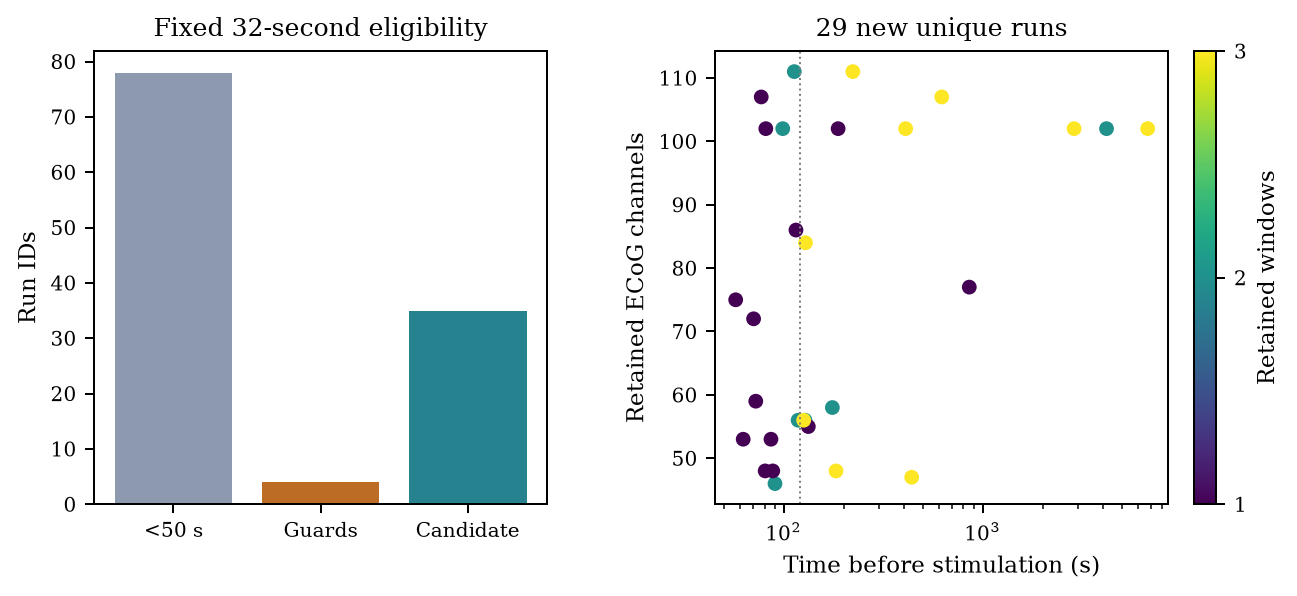

,participant,run,M,native_Hz,before_stimulation_s,retained,candidate,duplicate
0,01,021448,102,512,2877.9,3,3,False
1,01,031422,102,512,409.8,3,3,False
2,01,041224,102,512,4189.3,2,3,False
3,01,041550,102,512,6745.0,3,3,False
4,01,041750,102,512,187.5,1,2,False
5,01,061233,102,2048,98.8,2,2,False
6,01,061343,102,2048,81.2,1,1,False
7,02,021804,86,2048,115.1,1,2,False
8,03,031411,72,2048,70.5,1,1,False
9,04,031148,111,2048,112.9,2,2,False


In [2]:
plt=style()
fig,axes=plt.subplots(1,2,figsize=(7.2,3.2))
axes[0].bar(['<50 s','Guards','Candidate'],[78,4,35],color=['#8d99ae','#bc6c25','#26828e'])
axes[0].set(ylabel='Run IDs',title='Fixed 32-second eligibility')
active=dimensions[~dimensions.duplicate]
sc=axes[1].scatter(active.before_stimulation_s,active.M,c=active.retained,vmin=1,vmax=3,cmap='viridis',s=24)
axes[1].set(xscale='log',xlabel='Time before stimulation (s)',ylabel='Retained ECoG channels',title='29 new unique runs')
axes[1].axvline(120,color='.5',ls=':',lw=.8)
fig.colorbar(sc,ax=axes[1],ticks=[1,2,3],label='Retained windows')
for ax in axes: ax.set_box_aspect(1)
save(fig,RUN/'figures','cohort-scope')
display(Image(filename=str(RUN/'figures/cohort-scope.png')))
display(dimensions)

All 63 new candidate windows passed numerical QC; native review excluded seven. Below: a slow excursion, a few-sample discontinuity, and resolved sharp activity retained with a flag. Heatmaps show every channel across the full 32 s; native traces reveal details filtering/downsampling can obscure. Colour limits ±3 are **display saturation**, not signal clipping or cleaning. Window labels are zero-based.

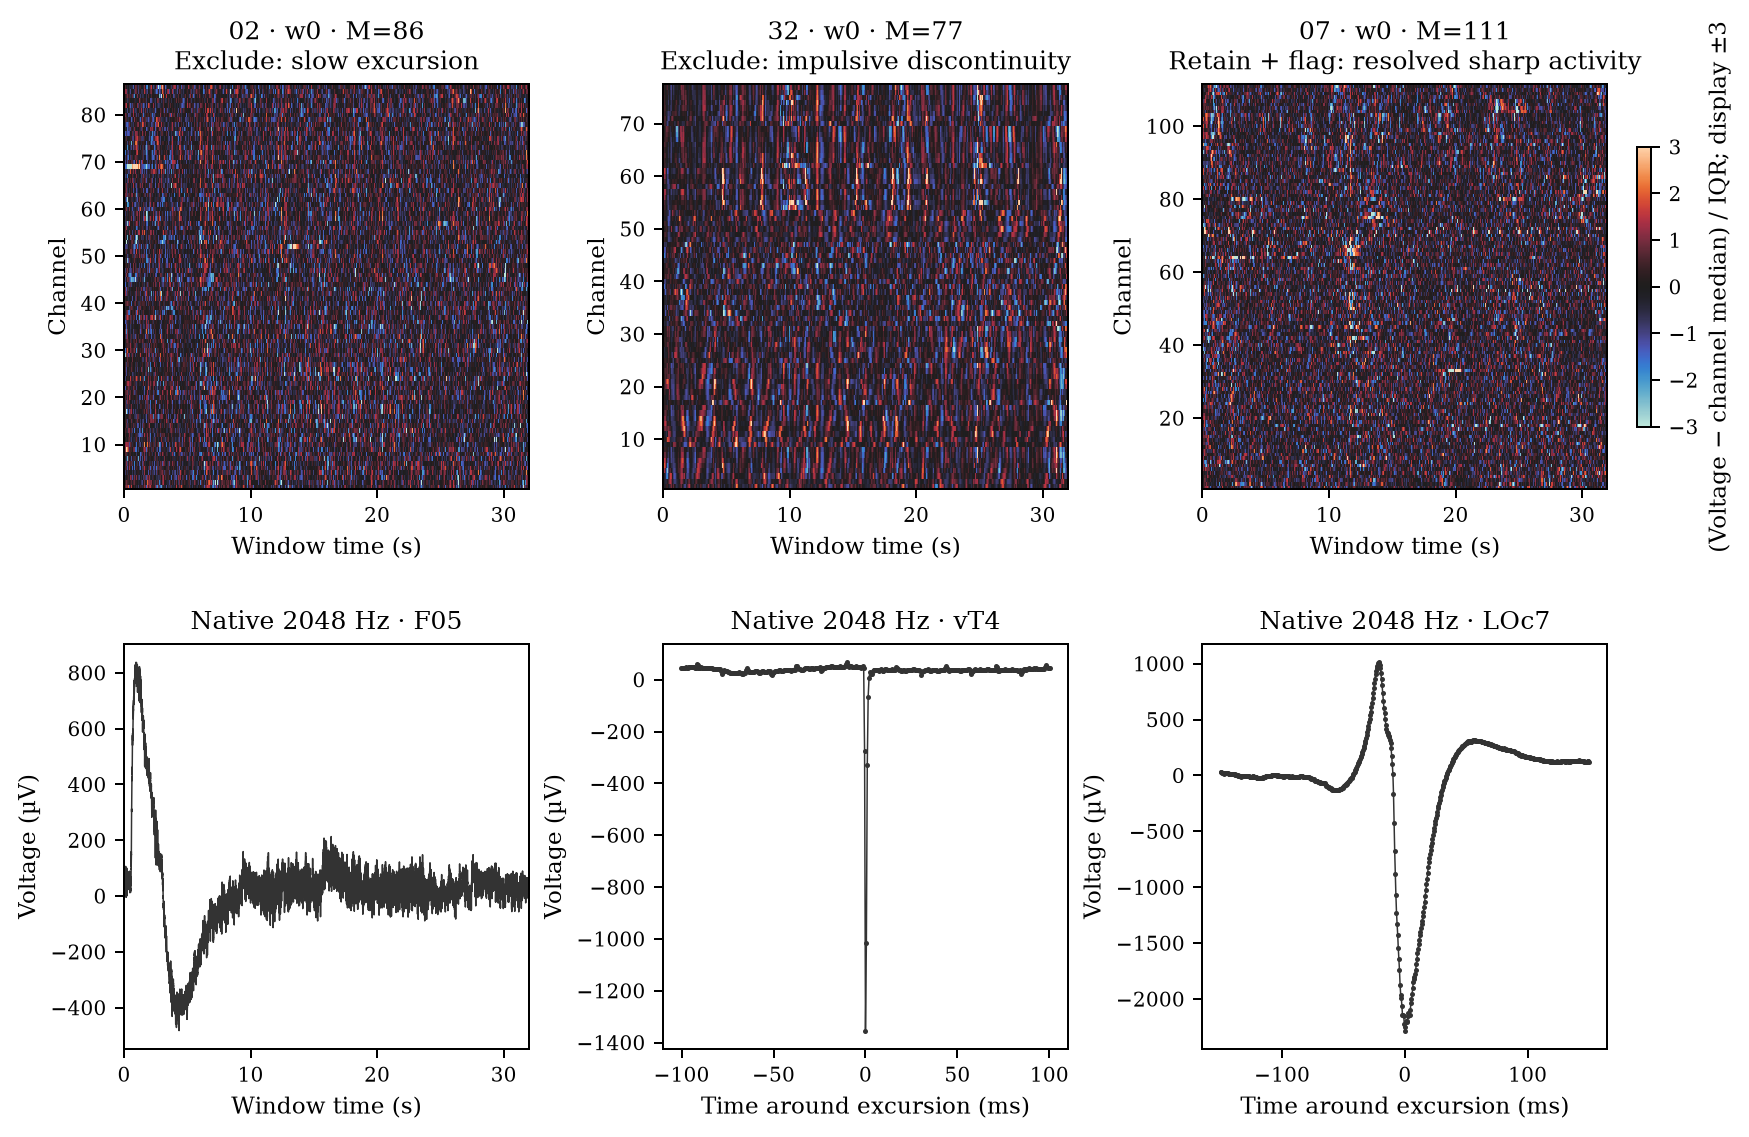

In [3]:
cleaning_examples(RUN, CONFIG/'cohort-review.json')
display(Image(filename=str(RUN/'figures/cleaning-decisions.png')))

Cleaning selects intervals and declared-good ECoG contacts; rejected transients are not interpolated away. Participant02 w0 is excluded, while the later w1 below is retained. Both heatmaps use per-channel median/IQR scaling; the reference changes, the interval does not. CAR subtracts the retained-channel mean; filtering retains 0.5–45 Hz before polyphase resampling to 128 Hz. Four-second filter pads are discarded; final input is channel-z-scored, M×4096. Native response data remain unchanged.

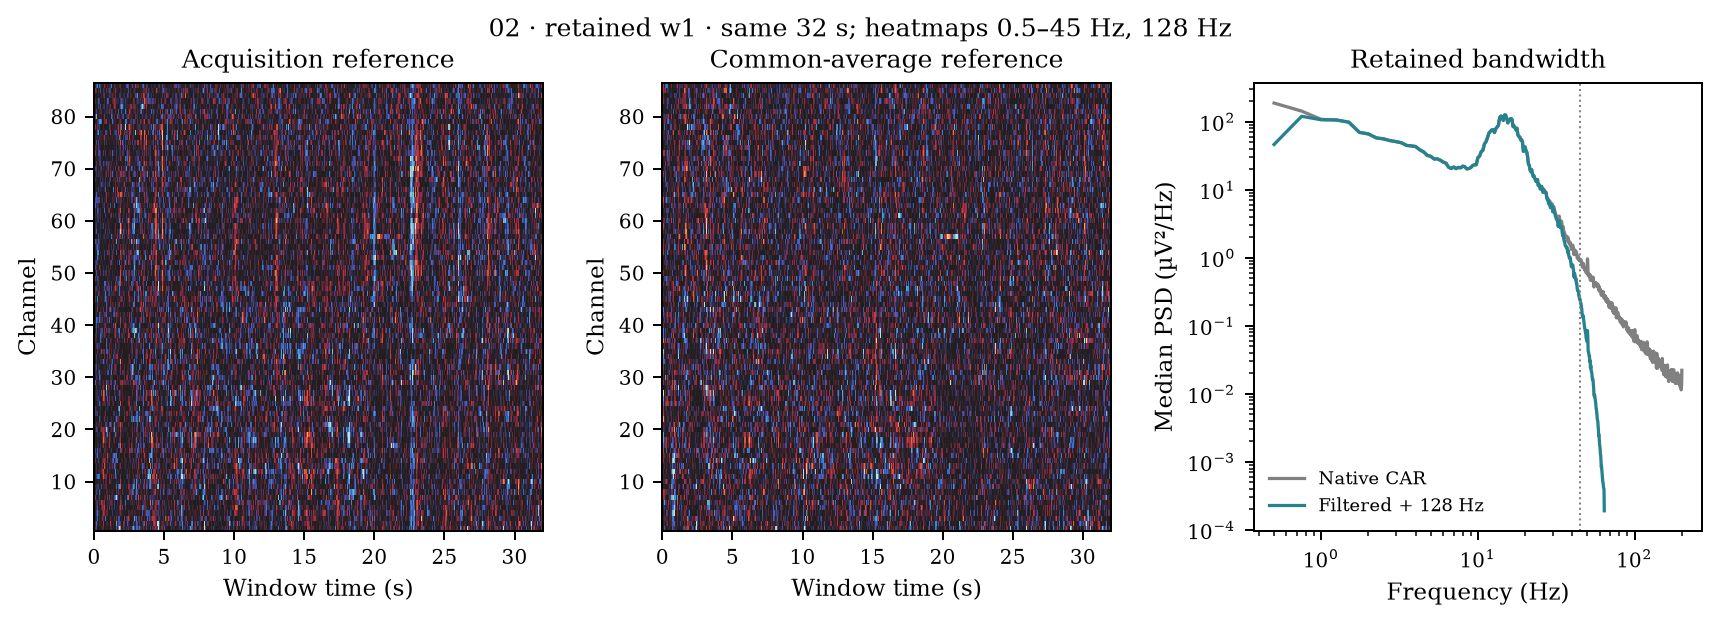

,participant,window,start_s,end_s,first_pulse_s,retain
0,02,0,9.00,41.00,115.07,False
1,02,1,57.28,89.28,115.07,True
2,32,0,9.00,41.00,855.67,False
3,32,1,53.11,85.11,855.67,False
4,32,2,97.22,129.22,855.67,True
5,07,0,9.00,41.00,222.32,True
6,07,1,77.93,109.93,222.32,True
7,07,2,181.32,213.32,222.32,True


In [4]:
display(Image(filename=str(RUN/'figures/cleaning-reference-bandwidth.png')))
examples=[]
for subject,run in [('02','021804'),('32','031446'),('07','021647')]:
    key=f'sub-ccepAgeUMCU{subject}_ses-1_task-SPESclin_run-{run}'
    report=json.loads((RUN/'scope'/f'{key}.json').read_text())
    for w in report['windows']:
        examples.append(dict(participant=subject,window=w['window'],start_s=round(w['start'],2),end_s=round(w['start']+32,2),first_pulse_s=round(report['first_stimulation'],2),retain=review['runs'][key][str(w['window'])]['accept']))
display(pd.DataFrame(examples))

Full p90 uses frozen fd0de71/r9, full edges and fixed 8/12 workers. At 14 October 10:13 UTC, 82/83 cohort outputs validate (95.48–97.51% finite edges; audit181254635); the final participant04 CAR window is running. All tables were submitted; no cohort failure observed. The pilot reference control exceeded its walltime and is queued for six hours with per-SPI checkpoints. Scientific interpretations remain pending.

Participant56/run021112 is an exact duplicate of run011112, computed once. Final expansion: **29 unique runs, 54 CAR windows + 29 reference controls = 83 tables**. With the original pilot: 34 unique runs, 24 participants, 102 tables. [Investigation and fixed latency test](../notes/ccep-pilot-261014.md#investigation-and-one-latency-test).